# Dreamerv3 Summary

This notebook consolidates the final benchmarking workflow for the ammonia process-control study. The analysis focuses on the strongest-performing configuration for each methodological section and reports the key results in a publication-ready form.

The objective is to present the representative outcome of the method under study while keeping the workflow scientifically reproducible, concise, and suitable for technical review.


# DreamerV3 Summary for the Ammonia Case Study

This notebook applies DreamerV3 to the same Haber-Bosch case study used in the BO notebook. It keeps the benchmark contract aligned with the BO setup:

- **Observation space:** the same 5D process vector from the DWSIM bridge.
- **Action space:** the same 7D normalized box in `[-1, 1]`.
- **Reward:** the same economic objective returned by the DWSIM bridge.

The critical difference is algorithmic framing. BO evaluates one candidate operating point per episode. Dreamer is therefore wrapped as a **single-step episodic benchmark**: reset gives the zero observation used by the BO workflow, Dreamer proposes one 7D action, the flowsheet is evaluated once, the economic reward is returned, and the episode ends.

That framing is deliberate and a bit adversarial to Dreamer. This is not the kind of sequential control problem Dreamer is strongest at, so the goal here is a controlled comparison, not an assumption that Dreamer should outperform BO on sample efficiency. The notebook keeps the model smaller than the Flappy Bird reference, adds a quick validation path, and caps the main run at **2000 episodes**.

Checkpoint continuation is supported in two ways:

1. Continue in place from the current run's `latest.pt`.
2. Branch into a new log directory, optionally seeding it from an earlier run so weights, replay, and metrics are preserved.

In [1]:
from __future__ import annotations



import importlib



import pandas as pd

from IPython.display import Markdown, display



import dreamerv3_haberbosch_helpers as dreamer_helpers



hb = importlib.reload(dreamer_helpers)

hb.set_plot_style()



WORKSPACE_DIR = hb.WORKSPACE_DIR

FULL_CFG = hb.DreamerExperimentConfig()

FULL_CFG.resume_from_checkpoint = "latest"

QUICK_CFG = hb.build_quick_validation_config(FULL_CFG)



display(Markdown(

    "**Design note:** the full Dreamer profile is configured for 2000 single-step episodes. The quick-validation profile is intentionally tiny and uses a separate log directory so you can test the full stack before spending the 2000-episode budget."

))

**Design note:** the full Dreamer profile is configured for 2000 single-step episodes. The quick-validation profile is intentionally tiny and uses a separate log directory so you can test the full stack before spending the 2000-episode budget.

In [2]:
preflight = hb.build_preflight_frame()
display(preflight)
if not preflight["ok"].all():
    missing = preflight.loc[~preflight["ok"], "item"].tolist()
    raise RuntimeError(f"Preflight failed for: {missing}")

,item,value,ok
0,Workspace,/Users/campatzis/Documents/Research,True
1,Flowsheet,/Users/campatzis/Documents/Research/DWSIM Simu...,True
2,Bridge Script,/Users/campatzis/Documents/Research/.dwsim_sup...,True
3,Rosetta Wrapper,/Users/campatzis/Documents/Research/.venv311-r...,True
4,Rosetta Python,/Users/campatzis/Documents/Research/.venv311-r...,True
5,Mono Root,/Users/campatzis/Documents/Research/.mono-runt...,True
6,DWSIM Automation Dir,/Applications/DWSIM.app/Contents/MonoBundle,True
7,Notebook Kernel Architecture,arm64,True


In [3]:
env = hb.make_haber_bosch_env()
try:
    smoke_test = hb.run_smoke_test(env)
finally:
    env.close()

display(smoke_test.to_frame(name="value"))
display(Markdown(
    "The smoke test is the cheapest meaningful end-to-end check: it verifies the same reset, action scaling, observation shape, and reward path used by the BO notebook before Dreamer is introduced."
))

,value
baseline_observation,"[0.0, 0.0, 0.0, 0.0, 0.0]"
step_observation,"[1.9237689962789544, 2448.9456451678902, 425.0..."
reward,737.350075
terminated,False
truncated,False
info,"{'nh3_kg_per_s': 1.9237689962789544, 'nh3_ton_..."


The smoke test is the cheapest meaningful end-to-end check: it verifies the same reset, action scaling, observation shape, and reward path used by the BO notebook before Dreamer is introduced.

## Configuration and Resume Logic

The table below compares the two run profiles. The full run is the main experiment. The quick-validation profile is only there to catch wiring errors before you spend a large DWSIM budget.

The default full configuration sets `resume_from_checkpoint = "latest"`. That means:

- a fresh log directory starts from scratch because there is no `latest.pt` yet
- rerunning the same notebook against an existing log directory resumes from `latest.pt` automatically
- increasing `FULL_CFG.target_episodes` lets you continue beyond the current run budget

In [4]:
config_table = hb.build_config_comparison_frame(FULL_CFG, QUICK_CFG)
resume_recipes = hb.build_resume_recipes(FULL_CFG.logdir)
display(config_table)
display(resume_recipes)
display(Markdown(
    "**Critical caveat:** resuming from an external checkpoint only preserves the model and optimizer state unless you also seed the new log directory from an older run. If you want the replay buffer too, set `seed_logdir_from` to the source run before starting the branch."
))

,logdir,target_episodes,prefill_steps,batch_size,batch_length,train_ratio,eval_episodes,eval_every_steps,log_every_steps,imag_horizon,resume_from_checkpoint
profile,,,,,,,,,,,
full,/Users/campatzis/Documents/Research/runs/dream...,2000,64,8,2,16.0,5,200,50,3,latest
quick_validation,/Users/campatzis/Documents/Research/runs/dream...,12,8,4,2,8.0,2,6,3,3,None


,scenario,logdir,seed_logdir_from,resume_from_checkpoint,what_it_preserves
0,Continue in place from latest,/Users/campatzis/Documents/Research/runs/dream...,None,latest,"Weights, optimizer state, replay, and logged m..."
1,Branch from explicit checkpoint,/Users/campatzis/Documents/Research/runs/dream...,/Users/campatzis/Documents/Research/runs/dream...,latest,Whole prior logdir if seeded first; otherwise ...


**Critical caveat:** resuming from an external checkpoint only preserves the model and optimizer state unless you also seed the new log directory from an older run. If you want the replay buffer too, set `seed_logdir_from` to the source run before starting the branch.

## Optional Backend Bootstrap

The helper can bootstrap Dreamer on demand, so this cell is optional. Run it once if you want to install or refresh the Dreamer runtime explicitly before the preflight or training cells.

In [5]:
BOOTSTRAP_DREAMER_RUNTIME = False

if BOOTSTRAP_DREAMER_RUNTIME:
    repo_dir = hb.bootstrap_dreamer_runtime(FULL_CFG.repo_url, FULL_CFG.repo_dir)
    print({"dreamer_repo": str(repo_dir)})
else:
    print("Set BOOTSTRAP_DREAMER_RUNTIME = True if you want to install Dreamer explicitly now. The preflight and training cells also bootstrap on demand.")

Set BOOTSTRAP_DREAMER_RUNTIME = True if you want to install Dreamer explicitly now. The preflight and training cells also bootstrap on demand.


## Dreamer Wiring Preflight

This is the Dreamer-specific cheap check. It patches the backend for CPU or MPS safety, builds the one-step Haber-Bosch adapter, and instantiates a Dreamer agent without launching a real training run.

Use the quick-validation profile here so the full 2000-episode log directory stays untouched until the wiring is clean.

In [6]:
RUN_DREAMER_PREFLIGHT = False

if RUN_DREAMER_PREFLIGHT:
    dreamer_preflight = hb.preflight_dreamer_agent(QUICK_CFG)
    display(pd.DataFrame([
        {key: value for key, value in dreamer_preflight.items() if key != "config_namespace"}
    ]))
else:
    print("Set RUN_DREAMER_PREFLIGHT = True to validate the Dreamer adapter and checkpoint hooks.")

Set RUN_DREAMER_PREFLIGHT = True to validate the Dreamer adapter and checkpoint hooks.


## Quick Validation Run

This path is intentionally small. It is for proving the notebook works end to end without spending the full experiment budget. The quick profile uses a separate run directory and resets it on each launch.

In [7]:
RUN_QUICK_VALIDATION = False

quick_result = hb.run_dreamer_training(QUICK_CFG, run_training=RUN_QUICK_VALIDATION)
quick_summary = quick_result.get("after", quick_result)
display(pd.DataFrame([
    {key: value for key, value in quick_summary.items() if key != "config_namespace"}
]))

/usr/local/bin/python3.10 -m pip install --upgrade pip wheel setuptools<82
/usr/local/bin/python3.10 -m pip install torch>=2.4.1 gym==0.22.0 ruamel.yaml tensorboard matplotlib moviepy einops
Using existing repository at /Users/campatzis/Documents/Research/third_party/dreamerv3_torch
No resume checkpoint selected. Training starts from scratch.
Dreamer launch is disabled.


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


,ran_training,current_env_steps,completed_episodes,remaining_episodes,target_episodes,resume_checkpoint,logdir,patch_report,device,tensorboard_dir,checkpoint_dir,resume_path
0,False,0,0,12,12,None,/Users/campatzis/Documents/Research/runs/dream...,{'networks.py': False},mps,/Users/campatzis/Documents/Research/runs/dream...,/Users/campatzis/Documents/Research/runs/dream...,None


## Full Dreamer Run

The full profile is the actual experiment and is configured for **2000 episodes**. By default it resumes from `latest.pt` in the same run directory if that checkpoint exists.

Continuation recipes:

- Continue in place: keep `FULL_CFG.logdir` unchanged, keep `FULL_CFG.resume_from_checkpoint = "latest"`, and increase `FULL_CFG.target_episodes`.
- Branch from an earlier run: set a new `FULL_CFG.logdir`, set `FULL_CFG.seed_logdir_from` to the source run directory, and keep `FULL_CFG.resume_from_checkpoint = "latest"`.

In [8]:
RUN_TRAINING = True

full_result = hb.run_dreamer_training(FULL_CFG, run_training=RUN_TRAINING)
full_summary = full_result.get("after", full_result)
display(pd.DataFrame([
    {key: value for key, value in full_summary.items() if key != "config_namespace"}
]))

/usr/local/bin/python3.10 -m pip install --upgrade pip wheel setuptools<82
/usr/local/bin/python3.10 -m pip install torch>=2.4.1 gym==0.22.0 ruamel.yaml tensorboard matplotlib moviepy einops
Using existing repository at /Users/campatzis/Documents/Research/third_party/dreamerv3_torch
No resume checkpoint selected. Training starts from scratch.
Logdir /Users/campatzis/Documents/Research/runs/dreamerv3_haber_bosch
Create envs.
Action Space Box(-1.0, 1.0, (7,), float32)
Prefill dataset (64 steps).
[Dreamer][Episode 25] Reward=1628.66 | AvgReward=-927.57 | BestReward=2303.98 | NH3=2.2809 kg/s | Power=2149.08 kW | Revenue=4105.55 $/h | EnergyCost=2476.89 $/h | EnvSteps=0 | Updates=0 | DatasetSize=25 | Device=mps | ElapsedMin=2.4
[Dreamer][Episode 50] Reward=2051.78 | AvgReward=-1376.64 | BestReward=2303.98 | NH3=2.1337 kg/s | Power=2713.45 kW | Revenue=3840.64 $/h | EnergyCost=1788.86 $/h | EnvSteps=0 | Updates=0 | DatasetSize=50 | Device=mps | ElapsedMin=4.7
Logger: (64 steps).
Simulate age

/Users/campatzis/Documents/Research/third_party/dreamerv3_torch/tools.py:747: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  self._scaler = torch.cuda.amp.GradScaler(enabled=use_amp)


Optimizer model_opt has 498181 variables.
Optimizer actor_opt has 67854 variables.
Optimizer value_opt has 98943 variables.
[0] 
Start evaluation.
[64] log_reward 1846.1 / log_nh3_kg_per_s 2.1 / log_nh3_ton_per_h 7.5 / log_power_kw 2112.9 / log_revenue_per_h 3750.9 / log_energy_cost_per_h 1904.8 / log_a1_normalized 0.9 / log_a1_physical 3.5 / log_a2_normalized -0.0 / log_a2_physical 54.5 / log_a3_normalized -0.4 / log_a3_physical 88.0 / log_a4_normalized -0.7 / log_a4_physical 172.8 / log_a5_normalized 0.9 / log_a5_physical 490.5 / log_a6_normalized -1.0 / log_a6_physical -29.3 / log_a7_normalized 0.9 / log_a7_physical 0.1 / eval_return 1596.6 / eval_length 1.0 / eval_episodes 5.0
moviepy is installed, but can't import moviepy.editor. Some packages could be missing [imageio, requests]
Start training.


/Users/campatzis/Documents/Research/third_party/dreamerv3_torch/models.py:116: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(self._use_amp):
/Users/campatzis/Documents/Research/third_party/dreamerv3_torch/models.py:160: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(self._use_amp):
/Users/campatzis/Documents/Research/third_party/dreamerv3_torch/models.py:299: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(self._use_amp):
/Users/campatzis/Documents/Research/third_party/dreamerv3_torch/models.py:323: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(self._use_amp):


[0] model_loss 40.3 / model_grad_norm 94.9 / state_loss 32.3 / reward_loss 5.2 / cont_loss 0.5 / kl_free 1.0 / dyn_scale 0.5 / rep_scale 0.1 / dyn_loss 3.8 / rep_loss 3.8 / kl 3.8 / prior_ent 43.2 / post_ent 41.3 / normed_target_mean -0.0 / normed_target_std 0.0 / normed_target_min -0.1 / normed_target_max -0.0 / EMA_005 -0.0 / EMA_095 -0.0 / value_mean -0.0 / value_std 0.0 / value_min -0.0 / value_max -0.0 / target_mean -0.1 / target_std 0.0 / target_min -0.1 / target_max -0.0 / imag_reward_mean -0.1 / imag_reward_std 0.0 / imag_reward_min -0.1 / imag_reward_max -0.0 / imag_action_mean 0.0 / imag_action_std 0.7 / imag_action_min -1.0 / imag_action_max 1.0 / actor_entropy 9.0 / actor_loss 0.0 / actor_grad_norm 0.0 / value_loss 8.2 / value_grad_norm 5.8 / update_count 100.0 / fps 0.0
[Dreamer][Episode 75] Reward=2209.31 | AvgReward=507.78 | BestReward=2689.90 | NH3=2.4602 kg/s | Power=2410.96 kW | Revenue=4428.44 $/h | EnergyCost=2219.13 $/h | EnvSteps=75 | Updates=100 | DatasetSize=75 

,current_env_steps,completed_episodes,remaining_episodes,target_episodes,resume_checkpoint,logdir
0,2264,2264,0,2000,/Users/campatzis/Documents/Research/runs/dream...,/Users/campatzis/Documents/Research/runs/dream...


## Metrics and Checkpoints

The cell below reads the most recent available metrics file. It prefers the full run directory and falls back to the quick-validation directory. The plots focus on the same process-facing quantities that matter in the BO notebook: reward, NH3 production, energy load, and the economics behind the reward.

,records,train_episode_logs,best_train_reward,best_eval_return,last_logged_reward,last_logged_nh3_kg_per_s,last_logged_revenue_per_h,last_logged_energy_cost_per_h
0,2330,2264,2711.665771,2508.802588,2503.587158,2.278407,4101.132812,1597.545654


,step,snapshot,created_at
6,1464,/Users/campatzis/Documents/Research/runs/dream...,1.777237e+09
7,1664,/Users/campatzis/Documents/Research/runs/dream...,1.777238e+09
8,1864,/Users/campatzis/Documents/Research/runs/dream...,1.777238e+09
9,2064,/Users/campatzis/Documents/Research/runs/dream...,1.777239e+09
10,2264,/Users/campatzis/Documents/Research/runs/dream...,1.777239e+09


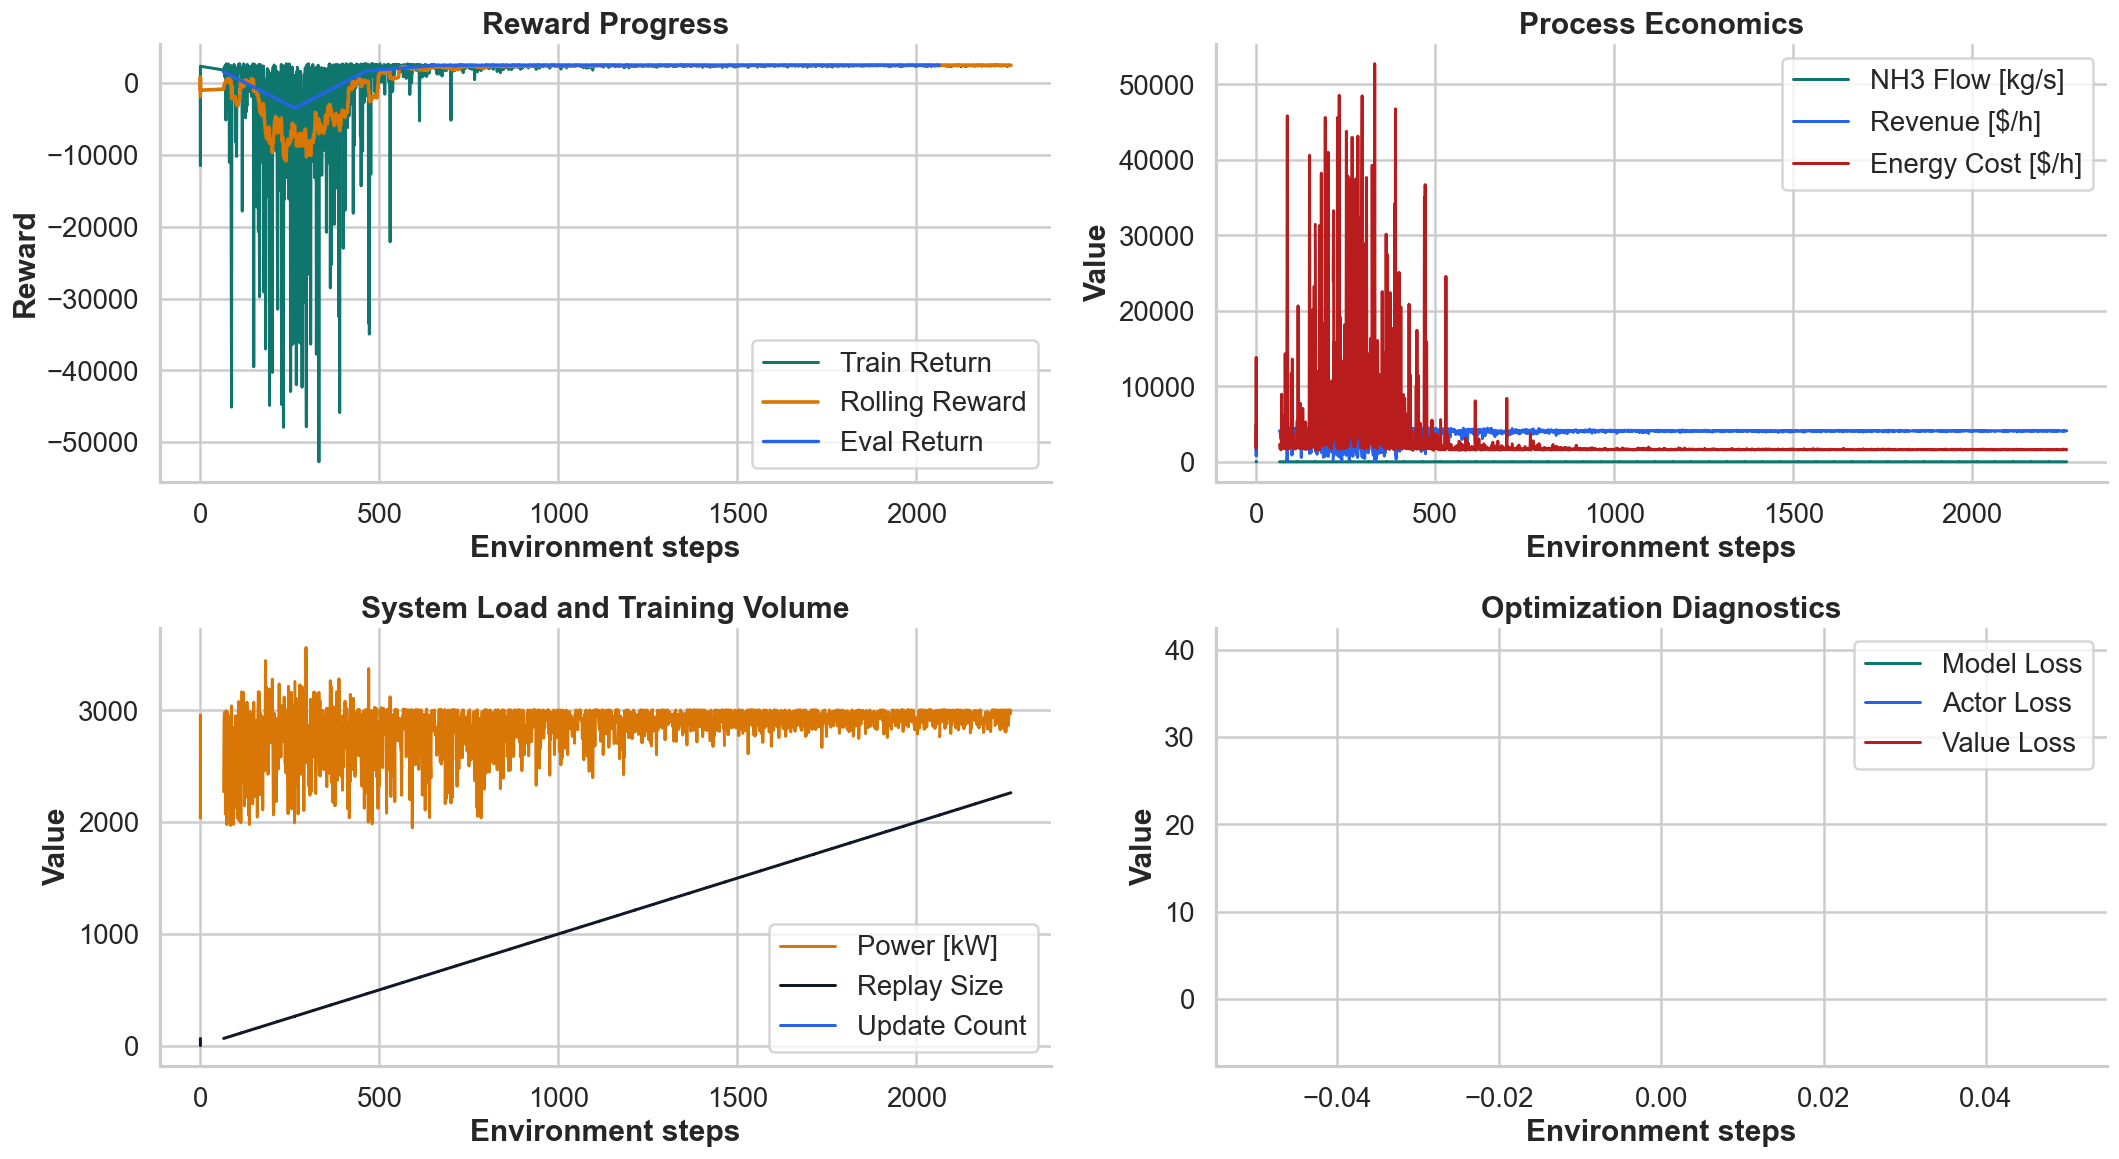

In [9]:
analysis_logdir = FULL_CFG.logdir if (FULL_CFG.logdir / "metrics.jsonl").exists() else QUICK_CFG.logdir

if (analysis_logdir / "metrics.jsonl").exists():
    metrics_df = hb.load_metrics_frame(analysis_logdir)
    checkpoint_index = hb.load_checkpoint_index(analysis_logdir)
    display(hb.summarize_metrics(metrics_df))
    if not checkpoint_index.empty:
        display(checkpoint_index.tail())
    hb.plot_training_diagnostics(metrics_df)
else:
    print(f"No metrics file found in {analysis_logdir}. Run the quick-validation or full training cell first.")